In [ ]:
import pandas as pd 
import requests
from bs4 import BeautifulSoup

'<!doctype html>\n<html data-n-head-ssr lang="en" data-n-head="%7B%22lang%22:%7B%22ssr%22:%22en%22%7D%7D">\n  <head >\n    <meta charset="UTF-8">\n    <meta name="viewport" content="width=device-width,initial-scale=1,minimum-scale=1">\n    <meta http-equiv="X-UA-Compatible" content="IE=edge"> \n    <link rel="manifest" href="/assets/next/manifest.json">\n    <style>@media only screen and (min-width:767px){.trp-img{width:400px!important;max-width:400px!important}}</style>\n    <script src="/static/js/env-runtime.js" defer></script>\n    <script>window.dataLayer=window.dataLayer||[],window.gtag=window.gtag||function(){window.dataLayer.push(arguments)},gtag("js",new Date),window.initialDate=(new Date).toISOString()</script>\n    <title>Top Companies in India | AmbitionBox</title><meta data-n-head="ssr" name="copyright" content="2025 AmbitionBox"><meta data-n-head="ssr" name="revisit-after" content="1 day"><meta data-n-head="ssr" name="application-name" content="AmbitionBox"><meta data-n-h
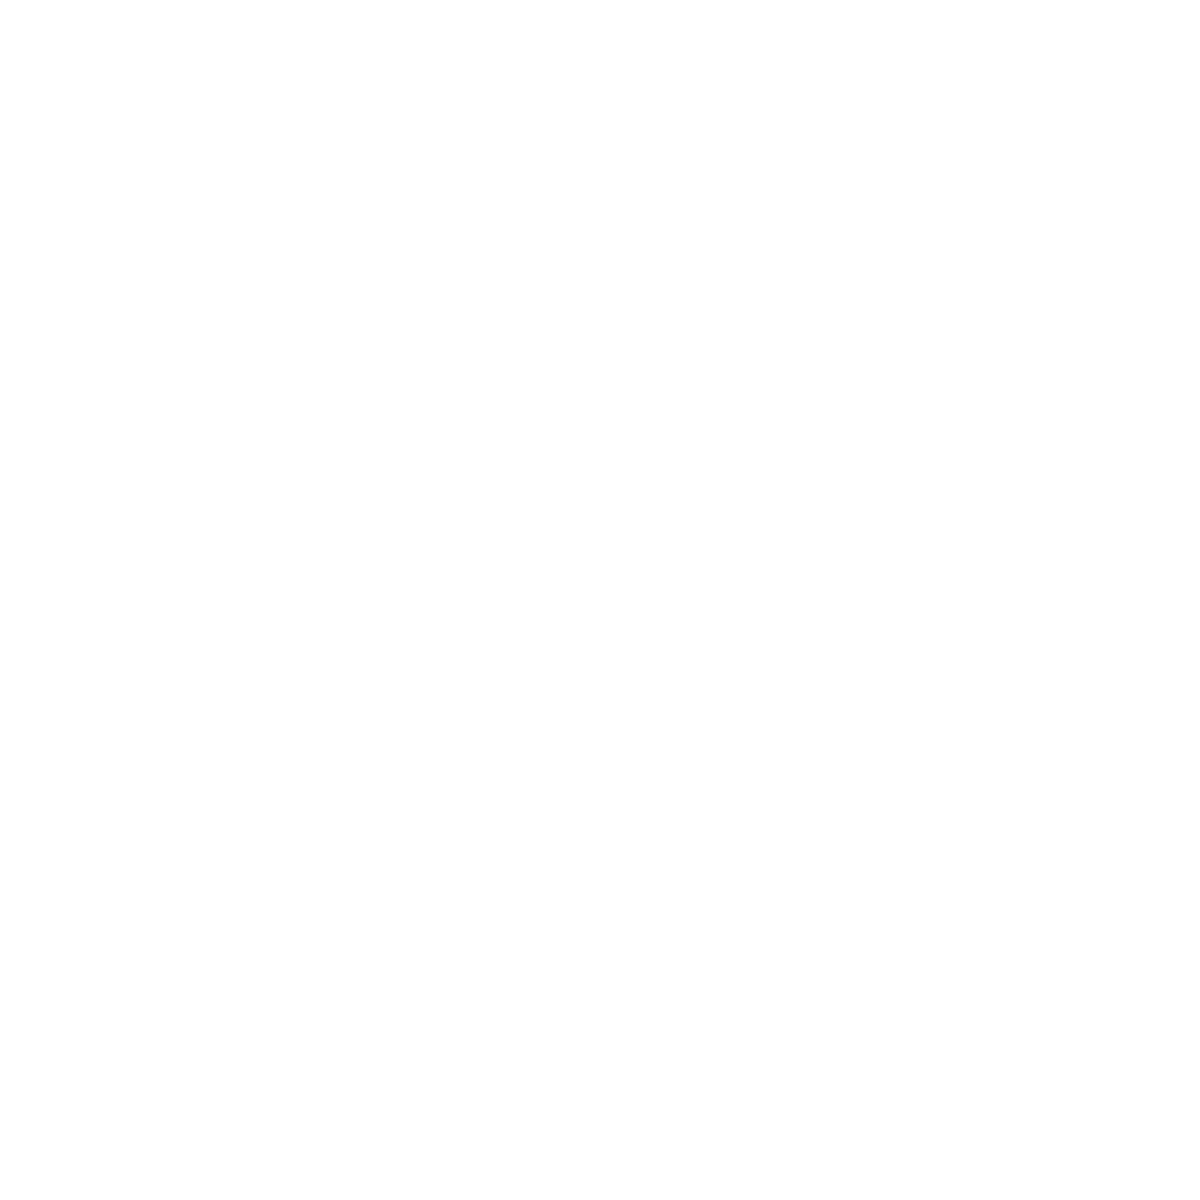

In [2]:
header ={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/58.0.3029.110 Safari/537.3'}
webpage=requests.get('https://www.ambitionbox.com/list-of-companies?page=1',headers=header).text
webpage


In [4]:
soup = BeautifulSoup(webpage, 'lxml')

In [5]:
len(soup.find_all('span', class_='companyCardWrapper__companyRatingCount'))


20

In [6]:
name = []
rating = []
reviews = []
salary = []
jobs = []
dis=[]
for i in soup.find_all('div', class_="companyCardWrapper"):
    name.append(i.find('h2').text.strip())
    rating.append(i.find('div', style="height:auto;padding-bottom:1px;").text.strip())
    reviews.append(i.find('span', class_="companyCardWrapper__companyRatingCount").text.strip())
    dis.append(i.find('span', class_="companyCardWrapper__interLinking").text.strip())
    sal = i.find('a', class_="companyCardWrapper__ActionWrapper", href=lambda x: x and '/salaries/' in x)
    if sal:
        salary_count = sal.find('span', class_="companyCardWrapper__ActionCount")
        salary.append(salary_count.text.strip())
    jo= i.find('a', class_="companyCardWrapper__ActionWrapper", href=lambda x: x and '/jobs/' in x)
    if jo:
        job_count = jo.find('span', class_="companyCardWrapper__ActionCount")
        jobs.append(job_count.text.strip() if job_count else "N/A")

In [7]:
df = pd.DataFrame({
	'Name': name,
	'Rating': rating,
	'Reviews': reviews,
	'Salary': salary,
	'Jobs': jobs,
    'Discription': dis
}, index=range(1, len(name)+1))
df = pd.DataFrame(df)

In [8]:
df

,Name,Rating,Reviews,Salary,Jobs,Discription
1,TCS,3.4,(1.1L),9.4L,1.1k,IT Services & Consulting | Bangalore / Bengalu...
2,Accenture,3.7,(67.5k),6.3L,34.7k,IT Services & Consulting | Bangalore / Bengalu...
3,Wipro,3.7,(60.6k),4.6L,6k,IT Services & Consulting | Bangalore / Bengalu...
4,Cognizant,3.7,(57.5k),5.8L,460,IT Services & Consulting | Hyderabad / Secunde...
5,Capgemini,3.7,(49.3k),4.6L,2k,IT Services & Consulting | Bangalore / Bengalu...
6,HDFC Bank,3.8,(47.4k),1.4L,175,Banking | Mumbai +1760 other locations
7,Infosys,3.5,(45.3k),5.1L,1.6k,IT Services & Consulting | Bangalore / Bengalu...
8,ICICI Bank,4.0,(43.2k),1.5L,2,Banking | Mumbai +1411 other locations
9,HCLTech,3.4,(42.3k),3.6L,272,IT Services & Consulting | Chennai +221 other ...
10,Tech Mahindra,3.4,(40.5k),2.8L,577,IT Services & Consulting | Hyderabad / Secunde...


In [ ]:

final = pd.DataFrame()
for j in range(1, 503):
    print(f"Scraping page {j}...")
    header = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) '
                      'AppleWebKit/537.36 (KHTML, like Gecko) '
                      'Chrome/58.0.3029.110 Safari/537.3'
    }
    url = f'https://www.ambitionbox.com/list-of-companies?page={j}'
    webpage = requests.get(url, headers=header).text
    soup = BeautifulSoup(webpage, 'lxml')
    name, rating, reviews, salary, jobs, dis = [], [], [], [], [], []

    for i in soup.find_all('div', class_="companyCardWrapper"):
        n = i.find('h2')
        name.append(n.text.strip() if n else "N/A")
        r = i.find('div', style="height:auto;padding-bottom:1px;")
        rating.append(r.text.strip() if r else "N/A")
        rv = i.find('span', class_="companyCardWrapper__companyRatingCount")
        reviews.append(rv.text.strip() if rv else "N/A")
        d = i.find('span', class_="companyCardWrapper__interLinking")
        dis.append(d.text.strip() if d else "N/A")
        sal = i.find('a', class_="companyCardWrapper__ActionWrapper", href=lambda x: x and '/salaries/' in x)
        if sal:
            salary_count = sal.find('span', class_="companyCardWrapper__ActionCount")
            salary.append(salary_count.text.strip() if salary_count else "N/A")
        else:
            salary.append("N/A")
        jo = i.find('a', class_="companyCardWrapper__ActionWrapper", href=lambda x: x and '/jobs/' in x)
        if jo:
            job_count = jo.find('span', class_="companyCardWrapper__ActionCount")
            jobs.append(job_count.text.strip() if job_count else "N/A")
        else:
            jobs.append("N/A")
    df = pd.DataFrame({
        'Name': name,
        'Rating': rating,
        'Reviews': reviews,
        'Salary': salary,
        'Jobs': jobs,
        'Description': dis
    }, index=range(1, len(name)+1))
    final = pd.concat([final, df], ignore_index=True)
print("✅ Scraping completed!")
print(final.head())
final.to_csv("ambitionbox_companies.csv", index=False)


Scraping page 1...
Scraping page 2...
Scraping page 3...
Scraping page 4...
Scraping page 5...
Scraping page 6...
Scraping page 7...
Scraping page 8...
Scraping page 9...
Scraping page 10...
Scraping page 11...
Scraping page 12...
Scraping page 13...
Scraping page 14...
Scraping page 15...
Scraping page 16...
Scraping page 17...
Scraping page 18...
Scraping page 19...
Scraping page 20...
Scraping page 21...
Scraping page 22...
Scraping page 23...
Scraping page 24...
Scraping page 25...
Scraping page 26...
Scraping page 27...
Scraping page 28...
Scraping page 29...
Scraping page 30...
Scraping page 31...
Scraping page 32...
Scraping page 33...
Scraping page 34...
Scraping page 35...
Scraping page 36...
Scraping page 37...
Scraping page 38...
Scraping page 39...
Scraping page 40...
Scraping page 41...
Scraping page 42...
Scraping page 43...
Scraping page 44...
Scraping page 45...
Scraping page 46...
Scraping page 47...
Scraping page 48...
Scraping page 49...
Scraping page 50...
Scraping 